# Analysis for the Project: Debt-Based License Suspension

## The Main Questions:
- What are the reasons for license suspensions? [Jassim]
- What % are not falling under safety related? [Rachel, Alberto]
- What % are debt based? [Sarah]
- How many people lose their license over nothing dangerous? [Yuan, Ethan]

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Classified Data

In [7]:
classified = pd.read_csv("classified_suspension_reasons.csv")

# Reinstated Distribution

In [3]:
#import reinstated data
columns_to_read_ri = ['Year Reinstated','Description']


df_ri_2020 = pd.read_csv("Reinstatement_information_2020.csv", usecols=columns_to_read_ri, dtype=str)
df_ri_2021 = pd.read_csv("Reinstatement_information_2021.csv", usecols=columns_to_read_ri, dtype=str)
df_ri_2022 = pd.read_csv("Reinstatement_information_2022 Jan-Nov.csv", usecols=columns_to_read_ri, dtype=str)

df_ri = pd.concat([df_ri_2020, df_ri_2021, df_ri_2022], axis=0)
df_ri

,Year Reinstated,Description
0,2020,NON-PAYMENT OF CHILD SUPPORT
1,2020,PROPERTY DAMAGE CLAIM
2,2020,NRVC Withdrawal
3,2020,NRVC Withdrawal
4,2020,94C35 __ PRESENT WITH HEROIN
...,...,...
27887,2022,Three Surchargeable Events
27888,2022,UNINSURED MOTOR VEHICLE c90 §34J
27889,2022,PAYMENT DEFAULT
27890,2022,COMPLAINT FRAUDULENT LICENSE/ID


In [13]:
#Top 10 reasons for license suspensions from 2020-2022

description_count_ri = df_ri.groupby("Description").size().sort_values(ascending=False)
total_count_ri = description_count_ri.sum()
description_percentages_ri = round((description_count_ri / total_count_ri) * 100, 2)

description_count_ri = description_count_ri.reset_index()

result1 = pd.merge(description_count_ri, description_percentages_ri.rename('Percentage'), on='Description')

result1.rename(columns={0: 'Number of Obeservations'}, inplace=True)

#Calculate the percentage of cases that can be explained by the top 10 reasons for license suspension 
#print(result1.head(10))
result1 = result1.iloc[:10]
result1["Percentage"].sum()
result1

,Description,Number of Obeservations,Percentage
0,PAYMENT DEFAULT,33861,22.85
1,Three Surchargeable Events,26529,17.90
2,NRVC Withdrawal,13212,8.92
3,Operating Under Influence (OUI),9437,6.37
4,Seven Surchargeable Events,6838,4.61
5,NON-PAYMENT OF CHILD SUPPORT,6335,4.27
6,Reciprocal Suspension,5749,3.88
7,Chemical Test Refusal,4593,3.10
8,ADMIN PER SE,4421,2.98
9,WARRANT,4249,2.87


In [15]:
#merge reinstated with classifications to classify all rows
result_ri = pd.merge(df_ri, classified, on='Description', how='left')
result_ri

,Year Reinstated,Description,count,dangerous,safety_related,debt_based
0,2020,NON-PAYMENT OF CHILD SUPPORT,56841,False,False,True
1,2020,PROPERTY DAMAGE CLAIM,7887,False,False,False
2,2020,NRVC Withdrawal,35650,True,True,False
3,2020,NRVC Withdrawal,35650,True,True,False
4,2020,94C35 __ PRESENT WITH HEROIN,25,False,False,False
...,...,...,...,...,...,...
148194,2022,Three Surchargeable Events,162663,False,False,False
148195,2022,UNINSURED MOTOR VEHICLE c90 §34J,1288,False,False,False
148196,2022,PAYMENT DEFAULT,180091,False,False,True
148197,2022,COMPLAINT FRAUDULENT LICENSE/ID,16599,False,False,False


In [17]:
#percentages aggregated by year
df = result_ri.groupby("Year Reinstated").agg({"count" : "count", "dangerous" : "sum", "debt_based": "sum"}	)
df['non-dangerous'] = df['count']- df['dangerous']
df['non debt-based'] = df['count']- df['debt_based']
df['Percent Safety Related'] = round((df['dangerous']/df['count']) * 100, 2)
df['Percent non-safety'] = round((df['non-dangerous']/df['count'])*100,2)
df['Percent Debt-Based'] = round((df['debt_based']/df['count']) * 100, 2)
df['Percent non debt-based'] = round((df['non debt-based']/df['count'])*100,2)
df

,count,dangerous,debt_based,non-dangerous,non debt-based,Percent Safety Related,Percent non-safety,Percent Debt-Based,Percent non debt-based
Year Reinstated,,,,,,,,,
2020,66610,23877,20634,42733,45976,35.85,64.15,30.98,69.02
2021,53697,17870,14002,35827,39695,33.28,66.72,26.08,73.92
2022,27892,9740,6285,18152,21607,34.92,65.08,22.53,77.47


In [18]:
#percentages for all three years combined 
print("From 2020 to 2022 for reinstated licenses, the percentage of non-safety related license suspensions is", round((df['non-dangerous'].sum()/df['count'].sum())*100,2),'%')
print("From 2020 to 2022 for reinstated licenses, the percentage of debt-based related license suspensions is", round((df['debt_based'].sum()/df['count'].sum())*100,2),'%')

From 2020 to 2022 for reinstated licenses, the percentage of non-safety related license suspensions is 65.26 %
From 2020 to 2022 for reinstated licenses, the percentage of debt-based related license suspensions is 27.61 %


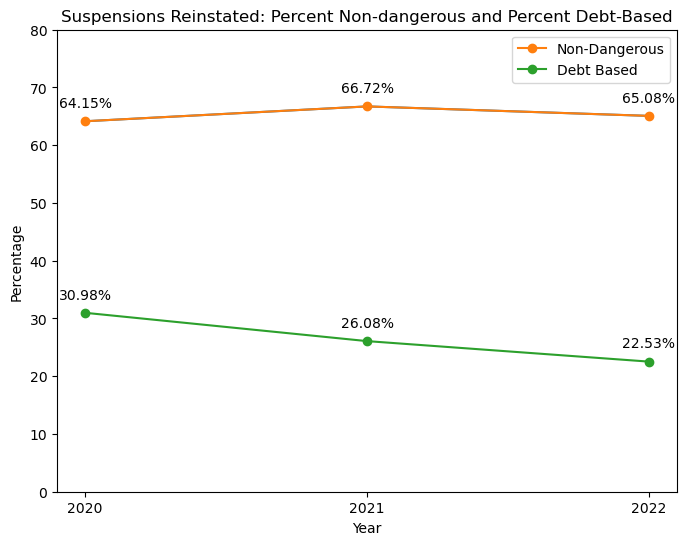

In [19]:
plt.figure(figsize=(8, 6))
plt.plot(df.index, df['Percent non-safety'])
plt.ylim(0, 80)

plt.xticks(df.index)
plt.xlabel('Year')
plt.ylabel('Percentage')
plt.title("Suspensions Reinstated: Percent Non-dangerous and Percent Debt-Based")

plt.plot(df.index, df['Percent non-safety'], label='Non-Dangerous', marker='o')
plt.plot(df.index, df['Percent Debt-Based'], label='Debt Based', marker='o')

for i, v in zip(df.index, df['Percent non-safety']):
    plt.annotate(
        f'{v}%',
        (i, v),
        textcoords="offset points",
        xytext=(0, 10),
        ha='center'
    )

for i, v in zip(df.index, df['Percent Debt-Based']):
    plt.annotate(
        f'{v}%',
        (i, v),
        textcoords="offset points",
        xytext=(0, 10),
        ha='center'
    )

plt.legend()
plt.show()

# Supended Information: All suspensions initiated in years 2020 - 2022

In [20]:
# Read the csv's 
columns_to_read_si = ['Year','Description']

df_si_2020 = pd.read_csv("Suspension_information_2020.csv", usecols=columns_to_read_si, dtype=str)
df_si_2021 = pd.read_csv("Suspension_information_2021.csv", usecols=columns_to_read_si, dtype=str)
df_si_2022 = pd.read_csv("Suspension_information_2022 Jan - Nov.csv", usecols=columns_to_read_si, dtype=str)

df_si = pd.concat([df_si_2020, df_si_2021, df_si_2022], axis=0)
df_si

,Year,Description
0,2020,Operating Under Influence (OUI)
1,2020,Operating Under Influence (OUI)
2,2020,Operating Under Influence (OUI)
3,2020,Ignition Interlock Device
4,2020,Operating Under Influence (OUI)
...,...,...
114595,2022,COMPLAINT REGULATORY
114596,2022,Operating Under Influence (OUI)
114597,2022,Operating Under Influence (OUI)
114598,2022,B26 - Driving while suspended


In [21]:
#Top 10 reasons for suspension and their cumulative sums
description_count_si = df_si.groupby("Description").size().sort_values(ascending=False)
total_count_si = description_count_si.sum()
description_percentages_si = round((description_count_si / total_count_si) * 100, 2)

description_count_si = description_count_si.reset_index()

result2 = pd.merge(description_count_si, description_percentages_si.rename('Percentage'), on='Description')

result2.rename(columns={0: 'Number of Obeservations'}, inplace=True)

#Calculate the percentage of cases that can be explained by the top 10 reasons for license suspension 
#print(result1.head(10))
result2 = result2.iloc[:10]
result2["Percentage"].sum()
result2

,Description,Number of Obeservations,Percentage
0,Three Surchargeable Events,57697,16.83
1,PAYMENT DEFAULT,51388,14.99
2,Reciprocal Suspension,37894,11.05
3,Major Disqualification,31593,9.22
4,Operating Under Influence (OUI),21727,6.34
5,Seven Surchargeable Events,11808,3.44
6,NON-PAYMENT OF CHILD SUPPORT,11194,3.27
7,Chemical Test Refusal,9776,2.85
8,IMMEDIATE THREAT,8448,2.46
9,ADMIN PER SE,8364,2.44


In [22]:
#merge to classify all rows in the dataset
result_si = pd.merge(df_si, classified, on='Description', how='left')
result_si

,Year,Description,count,dangerous,safety_related,debt_based
0,2020,Operating Under Influence (OUI),48814,True,True,False
1,2020,Operating Under Influence (OUI),48814,True,True,False
2,2020,Operating Under Influence (OUI),48814,True,True,False
3,2020,Ignition Interlock Device,54710,True,True,False
4,2020,Operating Under Influence (OUI),48814,True,True,False
...,...,...,...,...,...,...
342778,2022,COMPLAINT REGULATORY,7553,False,False,False
342779,2022,Operating Under Influence (OUI),48814,True,True,False
342780,2022,Operating Under Influence (OUI),48814,True,True,False
342781,2022,B26 - Driving while suspended,4748,False,False,False


In [23]:
#calculate percentages aggregated by year
df1 = result_si.groupby("Year").agg({"count" : "count", "dangerous" : "sum", "debt_based": "sum"})
df1['non-dangerous'] = df1['count']- df1['dangerous']
df1['non debt-based'] = df1['count']- df1['debt_based']
df1['Percent Safety Related'] = round((df1['dangerous']/df1['count']) * 100, 2)
df1['Percent non-safety'] = round((df1['non-dangerous']/df1['count'])*100,2)
df1['Percent Debt-Based'] = round((df1['debt_based']/df1['count']) * 100, 2)
df1['Percent non debt-based'] = round((df1['non debt-based']/df1['count'])*100,2)
df1

,count,dangerous,debt_based,non-dangerous,non debt-based,Percent Safety Related,Percent non-safety,Percent Debt-Based,Percent non debt-based
Year,,,,,,,,,
2020,116841,55114,21142,61727,95699,47.17,52.83,18.09,81.91
2021,111342,47733,20052,63609,91290,42.87,57.13,18.01,81.99
2022,114600,46453,23160,68147,91440,40.53,59.47,20.21,79.79


In [24]:
#calculate the percentages for all three years 2020-2022
print("From 2020 to 2022 for all licenses suspended, the percentage of non-safety related license suspensions is", round((df1['non-dangerous'].sum()/df1['count'].sum())*100,2),'%')
print("From 2020 to 2022 for all licenses suspended, the percentage of debt-based related license suspensions is", round((df1['debt_based'].sum()/df1['count'].sum())*100,2),'%')

From 2020 to 2022 for all licenses suspended, the percentage of non-safety related license suspensions is 56.44 %
From 2020 to 2022 for all licenses suspended, the percentage of debt-based related license suspensions is 18.77 %


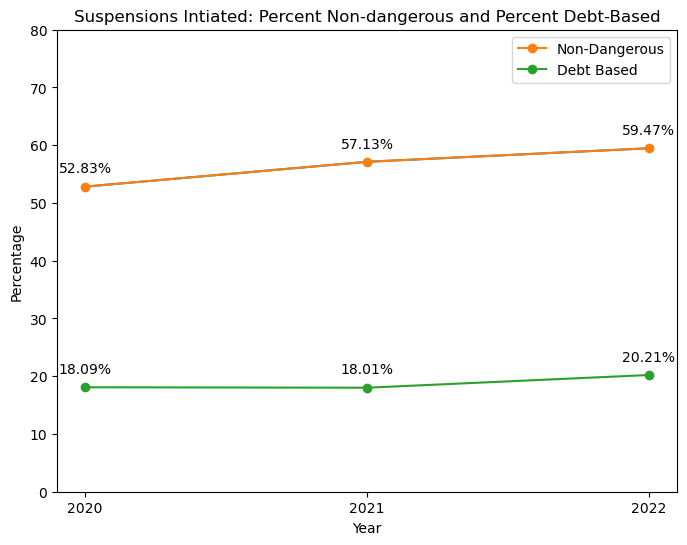

In [25]:
plt.figure(figsize=(8, 6))
plt.plot(df1.index, df1['Percent non-safety'])
plt.ylim(0, 80)

plt.xticks(df1.index)
plt.xlabel('Year')
plt.ylabel('Percentage')
plt.title("Suspensions Intiated: Percent Non-dangerous and Percent Debt-Based")

plt.plot(df1.index, df1['Percent non-safety'], label='Non-Dangerous', marker='o')
plt.plot(df1.index, df1['Percent Debt-Based'], label='Debt Based', marker='o')

for i, v in zip(df1.index, df1['Percent non-safety']):
    plt.annotate(
        f'{v}%',
        (i, v),
        textcoords="offset points",
        xytext=(0, 10),
        ha='center'
    )

for i, v in zip(df1.index, df1['Percent Debt-Based']):
    plt.annotate(
        f'{v}%',
        (i, v),
        textcoords="offset points",
        xytext=(0, 10),
        ha='center'
    )
plt.legend()
plt.show()
